# DuckDB Masterclass — Capítulo 13
## Profiling, EXPLAIN ANALYZE e execução out-of-core

**Edição didática para estudo autônomo e publicação**  
**Contexto:** Operations Analytics e telecomunicações | **Dados:** sintéticos  
**Roteiro:** hipótese → executar → validar → interpretar → desafio → autoavaliação.

> Execute as células **de cima para baixo** em um kernel limpo. Resultados reais só devem ser salvos depois da execução no seu ambiente. Não publique dados privados, credenciais ou caminhos absolutos.

## 13.1 — Objetivos e diagnóstico

- Diferenciar plano estimado e execução medida.
- Inspecionar `EXPLAIN` e `EXPLAIN ANALYZE`.
- Entender `memory_limit` e `temp_directory`.
- Não concluir que houve spill apenas por configurar memória pequena.

**Pergunta de partida:** que risco operacional aparece quando utilizamos essa tecnologia de forma inadequada?

## 13.2 — Conceitos essenciais

`EXPLAIN` mostra estrutura planejada; `EXPLAIN ANALYZE` executa a consulta e relata observações. Out-of-core ocorre quando certas operações utilizam armazenamento temporário para ultrapassar RAM disponível. Memória reduzida por si só **não comprova spill**, e configurações extremas podem falhar.

### 🗺️ Modelo visual — Profiling, EXPLAIN ANALYZE e execução out-of-core

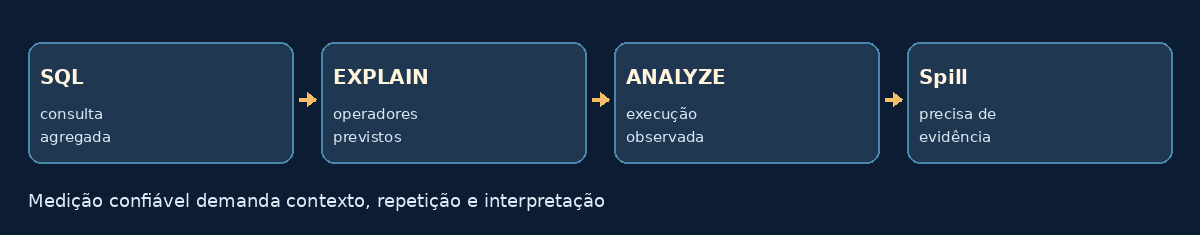

*Ilustração esquemática; não representa medição experimental.*

## 13.3 — Preparação e pré-requisitos

- Kernel recomendado: **Python (DuckDB Masterclass)**.
- Instale dependências ausentes no seu ambiente, fora do fluxo dos laboratórios.
- Cada arquivo produzido é sintético e deve ser salvo em pasta temporária ou `dados/` (ignorada pelo Git).
- Não execute instalação de extensões externas sem entender a necessidade, conectividade e eventuais custos.

## 13.4 — 🔬 Criar dados sintéticos

**Hipótese / tarefa:** Gerar 50 mil eventos simples para agregação.

In [ ]:
import duckdb
from IPython.display import display
con = duckdb.connect(':memory:')
print('DuckDB:', duckdb.__version__)
con.execute("CREATE TABLE eventos AS SELECT i id,'R'||CAST(i%10 AS VARCHAR) regiao,i%1000 valor FROM range(50000) t(i)")
assert con.execute('SELECT COUNT(*) FROM eventos').fetchone()[0]==50000

**Interpretação e limite:** Evita dataset externo e custo de rede.

## 13.5 — 🔬 Inspecionar EXPLAIN

**Hipótese / tarefa:** Observar operadores planejados em consulta agregada.

In [ ]:
plano=con.execute('EXPLAIN SELECT regiao,AVG(valor) media FROM eventos GROUP BY regiao').fetchone()[1]
print(plano)
assert isinstance(plano,str) and len(plano)>0

**Interpretação e limite:** Não equivale a tempo efetivo.

## 13.6 — 🔬 Executar EXPLAIN ANALYZE

**Hipótese / tarefa:** Observar tempos e operadores efetivamente executados.

In [ ]:
analisado=con.execute('EXPLAIN ANALYZE SELECT regiao,AVG(valor) media FROM eventos GROUP BY regiao').fetchone()[1]
print(analisado)
assert isinstance(analisado,str) and len(analisado)>0

**Interpretação e limite:** Medidas de uma execução não são benchmark robusto.

## 13.7 — 🔬 Inspecionar configuração sem forçar spill

**Hipótese / tarefa:** Ver opções de memória e pasta temporária, sem induzir falhas artificiais.

In [ ]:
config=con.execute("SELECT name,value FROM duckdb_settings() WHERE name IN ('memory_limit','temp_directory') ORDER BY name").df()
display(config)
print('Não afirmamos spill: nenhuma evidência de escrita temporária foi instrumentada neste exemplo.')

**Interpretação e limite:** Sem evidência real, não registrar spill como comprovado.

## 13.8 — 🎯 Desafio profissional

Qual evidência seria necessária para afirmar que uma agregação usou disco temporário sob pressão de memória?

**Critério de aceite:** apresentar a consulta ou procedimento, verificar uma hipótese e explicar pelo menos uma limitação. Resolva antes de consultar a referência abaixo.

### 🧠 Solução comentada / critérios de conferência

Exigir profiling compatível, inspeção de arquivos temporários e comparação entre cenários; apenas setar `memory_limit` não prova execução out-of-core.

## 13.9 — Autoavaliação

1. Explique o recurso sem reproduzir o código.
2. O que foi efetivamente demonstrado?
3. Que caso-limite poderia invalidar a interpretação?
4. Como validar a resposta com `assert`, SQL ou inspeção do plano?
5. Quando aplicaria isso em operações de telecomunicações?

**Gabarito orientador:** consulte a solução comentada do desafio e compare sua resposta com os resultados efetivamente observados; não conclua propriedades de performance ou produção sem evidência.

## 13.10 — Referências, reprodução e publicação

- [EXPLAIN](https://duckdb.org/docs/stable/guides/meta/explain.html)
- [Profiling](https://duckdb.org/docs/stable/dev/profiling.html)
- [Spilling to Disk](https://duckdb.org/docs/stable/guides/performance/how_to_tune_workloads.html)

**Notas de engenharia:** A consulta atual é pequena e demonstra profiling, não overflow de RAM.

**Checklist editorial:** executar `Restart & Run All` quando aplicável; salvar saídas úteis; revisar integridade, privacidade, dependências e gráficos antes do `git add`.